<center><h1>Li_Sumi_HW6</h1></center>

Name: Li Sumi
<br>
Github Username: SumiLi-1
<br>
USC ID: 5751493481

## 1. Tree-Based Methods

In [1]:
# 导入数据、绘图、模型、交叉验证和评价指标需要的套件。
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.utils import resample
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')
RANDOM_STATE, N_JOBS = 552, -1
sns.set_theme(style='whitegrid')

# 输入 0/1 标签、预测类别和预测为正类的概率，统一输出题目要求的结果。
def evaluate(y_true, y_pred, y_prob, name):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    auc, error = roc_auc_score(y_true, y_prob), 1 - np.mean(y_true == y_pred)
    cost = 10 * fp + 500 * fn  # 作业数据说明给出的误报／漏报成本。
    print(f'\n{name}\n', pd.DataFrame(cm, index=['Actual negative', 'Actual positive'], columns=['Predicted negative', 'Predicted positive']))
    print(f'Error rate={error:.4f}; AUC={auc:.4f}; Business cost={cost:,}')
    print(classification_report(y_true, y_pred, target_names=['neg', 'pos'], digits=4))
    ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(cmap='Blues'); plt.title(name + '：混淆矩阵'); plt.show()
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'AUC={auc:.4f}'); plt.plot([0,1],[0,1],'--',color='gray')
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title(name + '：ROC'); plt.legend(); plt.show()
    return {'cm': cm, 'error': error, 'auc': auc, 'cost': cost}


### (a) Download the APS Failure data

In [2]:
# 使用相对路径，确保整个 HW6 文件夹移动后仍能运行。前 20 行是版权说明，第 21 行才是 CSV 表头；na 表示缺失值。
data_dir = Path('data')
train_raw = pd.read_csv(data_dir / 'aps_failure_training_set.csv', skiprows=20, na_values='na', skipinitialspace=True)
test_raw = pd.read_csv(data_dir / 'aps_failure_test_set.csv', skiprows=20, na_values='na', skipinitialspace=True)
print('Training set:', train_raw.shape, '; Test set:', test_raw.shape)
display(train_raw.head())


Training set: (60000, 171) ; Test set: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [3]:
# class 以外的 170 列是特征；将 pos 编码为 1，neg 编码为 0。
features = [c for c in train_raw.columns if c != 'class']
X_train_raw = train_raw[features].apply(pd.to_numeric, errors='coerce')
X_test_raw = test_raw[features].apply(pd.to_numeric, errors='coerce')
y_train = (train_raw['class'].str.strip() == 'pos').astype(int)
y_test = (test_raw['class'].str.strip() == 'pos').astype(int)

# 缺失概况和中位数填补：fit 只使用训练集，transform 才作用到测试集。
display(pd.DataFrame({'Missing count': X_train_raw.isna().sum(), 'Missing ratio': X_train_raw.isna().mean()}).sort_values('Missing count', ascending=False).head(10))
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=features, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=features, index=X_test_raw.index)
assert not X_train.isna().any().any() and not X_test.isna().any().any()


,Missing count,Missing ratio
br_000,49264,0.821067
bq_000,48722,0.812033
bp_000,47740,0.795667
bo_000,46333,0.772217
ab_000,46329,0.772150
cr_000,46329,0.772150
bn_000,44009,0.733483
bm_000,39549,0.659150
bl_000,27277,0.454617
bk_000,23034,0.383900


In [4]:
# CV=样本标准差/样本均值。均值接近 0 时数值可能不稳定，因此按绝对 CV 排序。
cv_table = pd.DataFrame({'mean': X_train.mean(), 'std': X_train.std(ddof=1)})
cv_table['CV'] = cv_table['std'] / cv_table['mean']
cv_table['abs_CV'] = cv_table['CV'].abs().replace([np.inf, -np.inf], np.nan)
cv_table = cv_table.sort_values('abs_CV', ascending=False)
display(cv_table.head(20))

,mean,std,CV,abs_CV
cf_000,143107.534133,3.504525e+07,244.887517,244.887517
co_000,143330.017733,3.504525e+07,244.507385,244.507385
ad_000,143438.292067,3.504525e+07,244.322816,244.322816
cs_009,770.509700,1.833278e+05,237.930554,237.930554
dh_000,4392.640833,5.412441e+05,123.216097,123.216097
dj_000,37.271333,4.379166e+03,117.494225,117.494225
ag_000,219.157733,2.036364e+04,92.917755,92.917755
as_000,125.407900,1.095219e+04,87.332500,87.332500
ay_009,1149.619633,9.741156e+04,84.733735,84.733735
ak_000,907.660700,7.299859e+04,80.424975,80.424975


#### (iii) Plot a correlation matrix

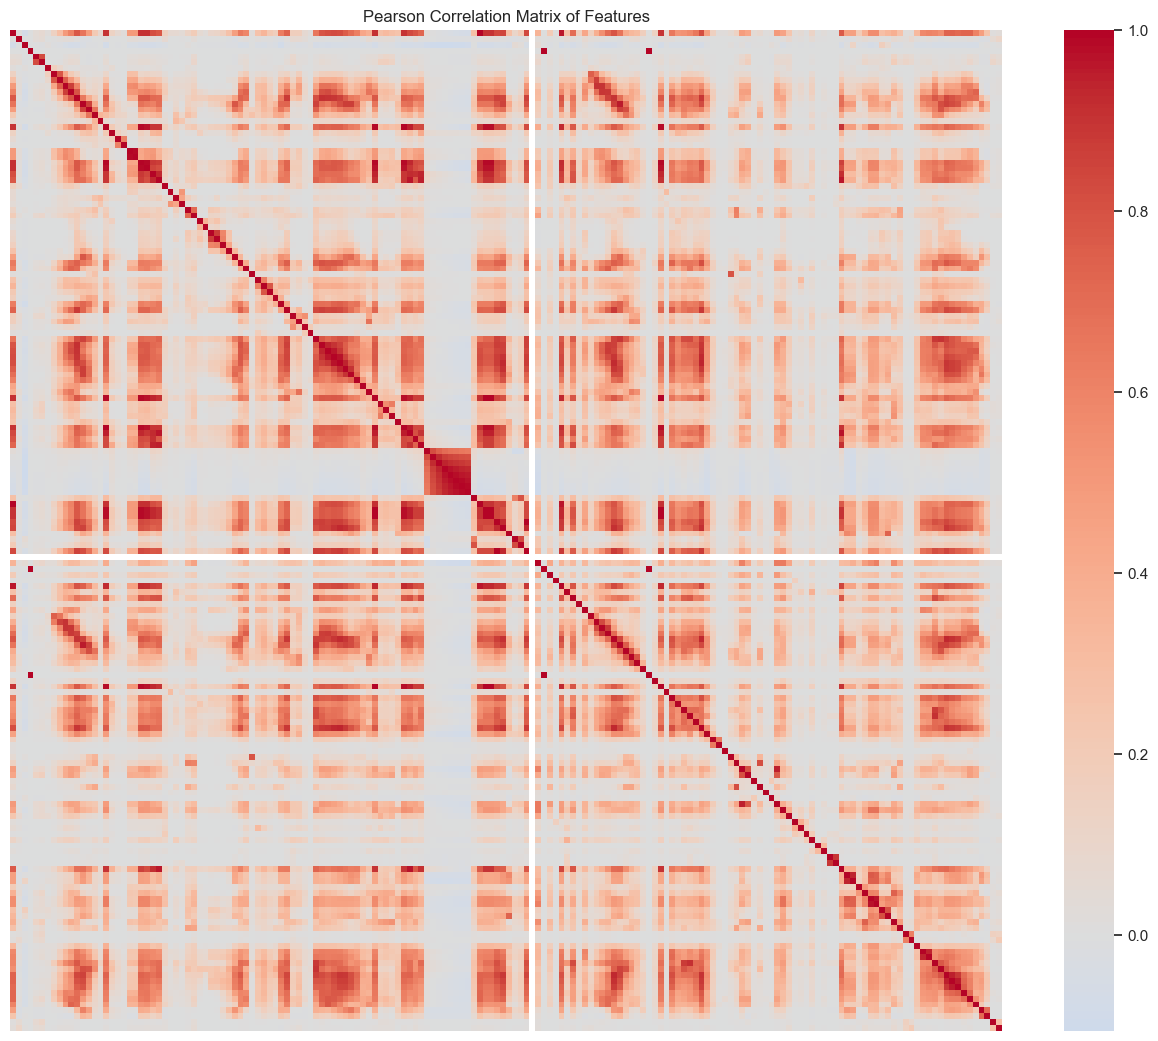

In [5]:
# 170×170 热图显示整体相关性；隐藏标签以避免图形过度拥挤。
plt.figure(figsize=(16, 13))
sns.heatmap(X_train.corr(), cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('Pearson Correlation Matrix of Features'); plt.show()


#### (iv) Make scatter plots and box plots

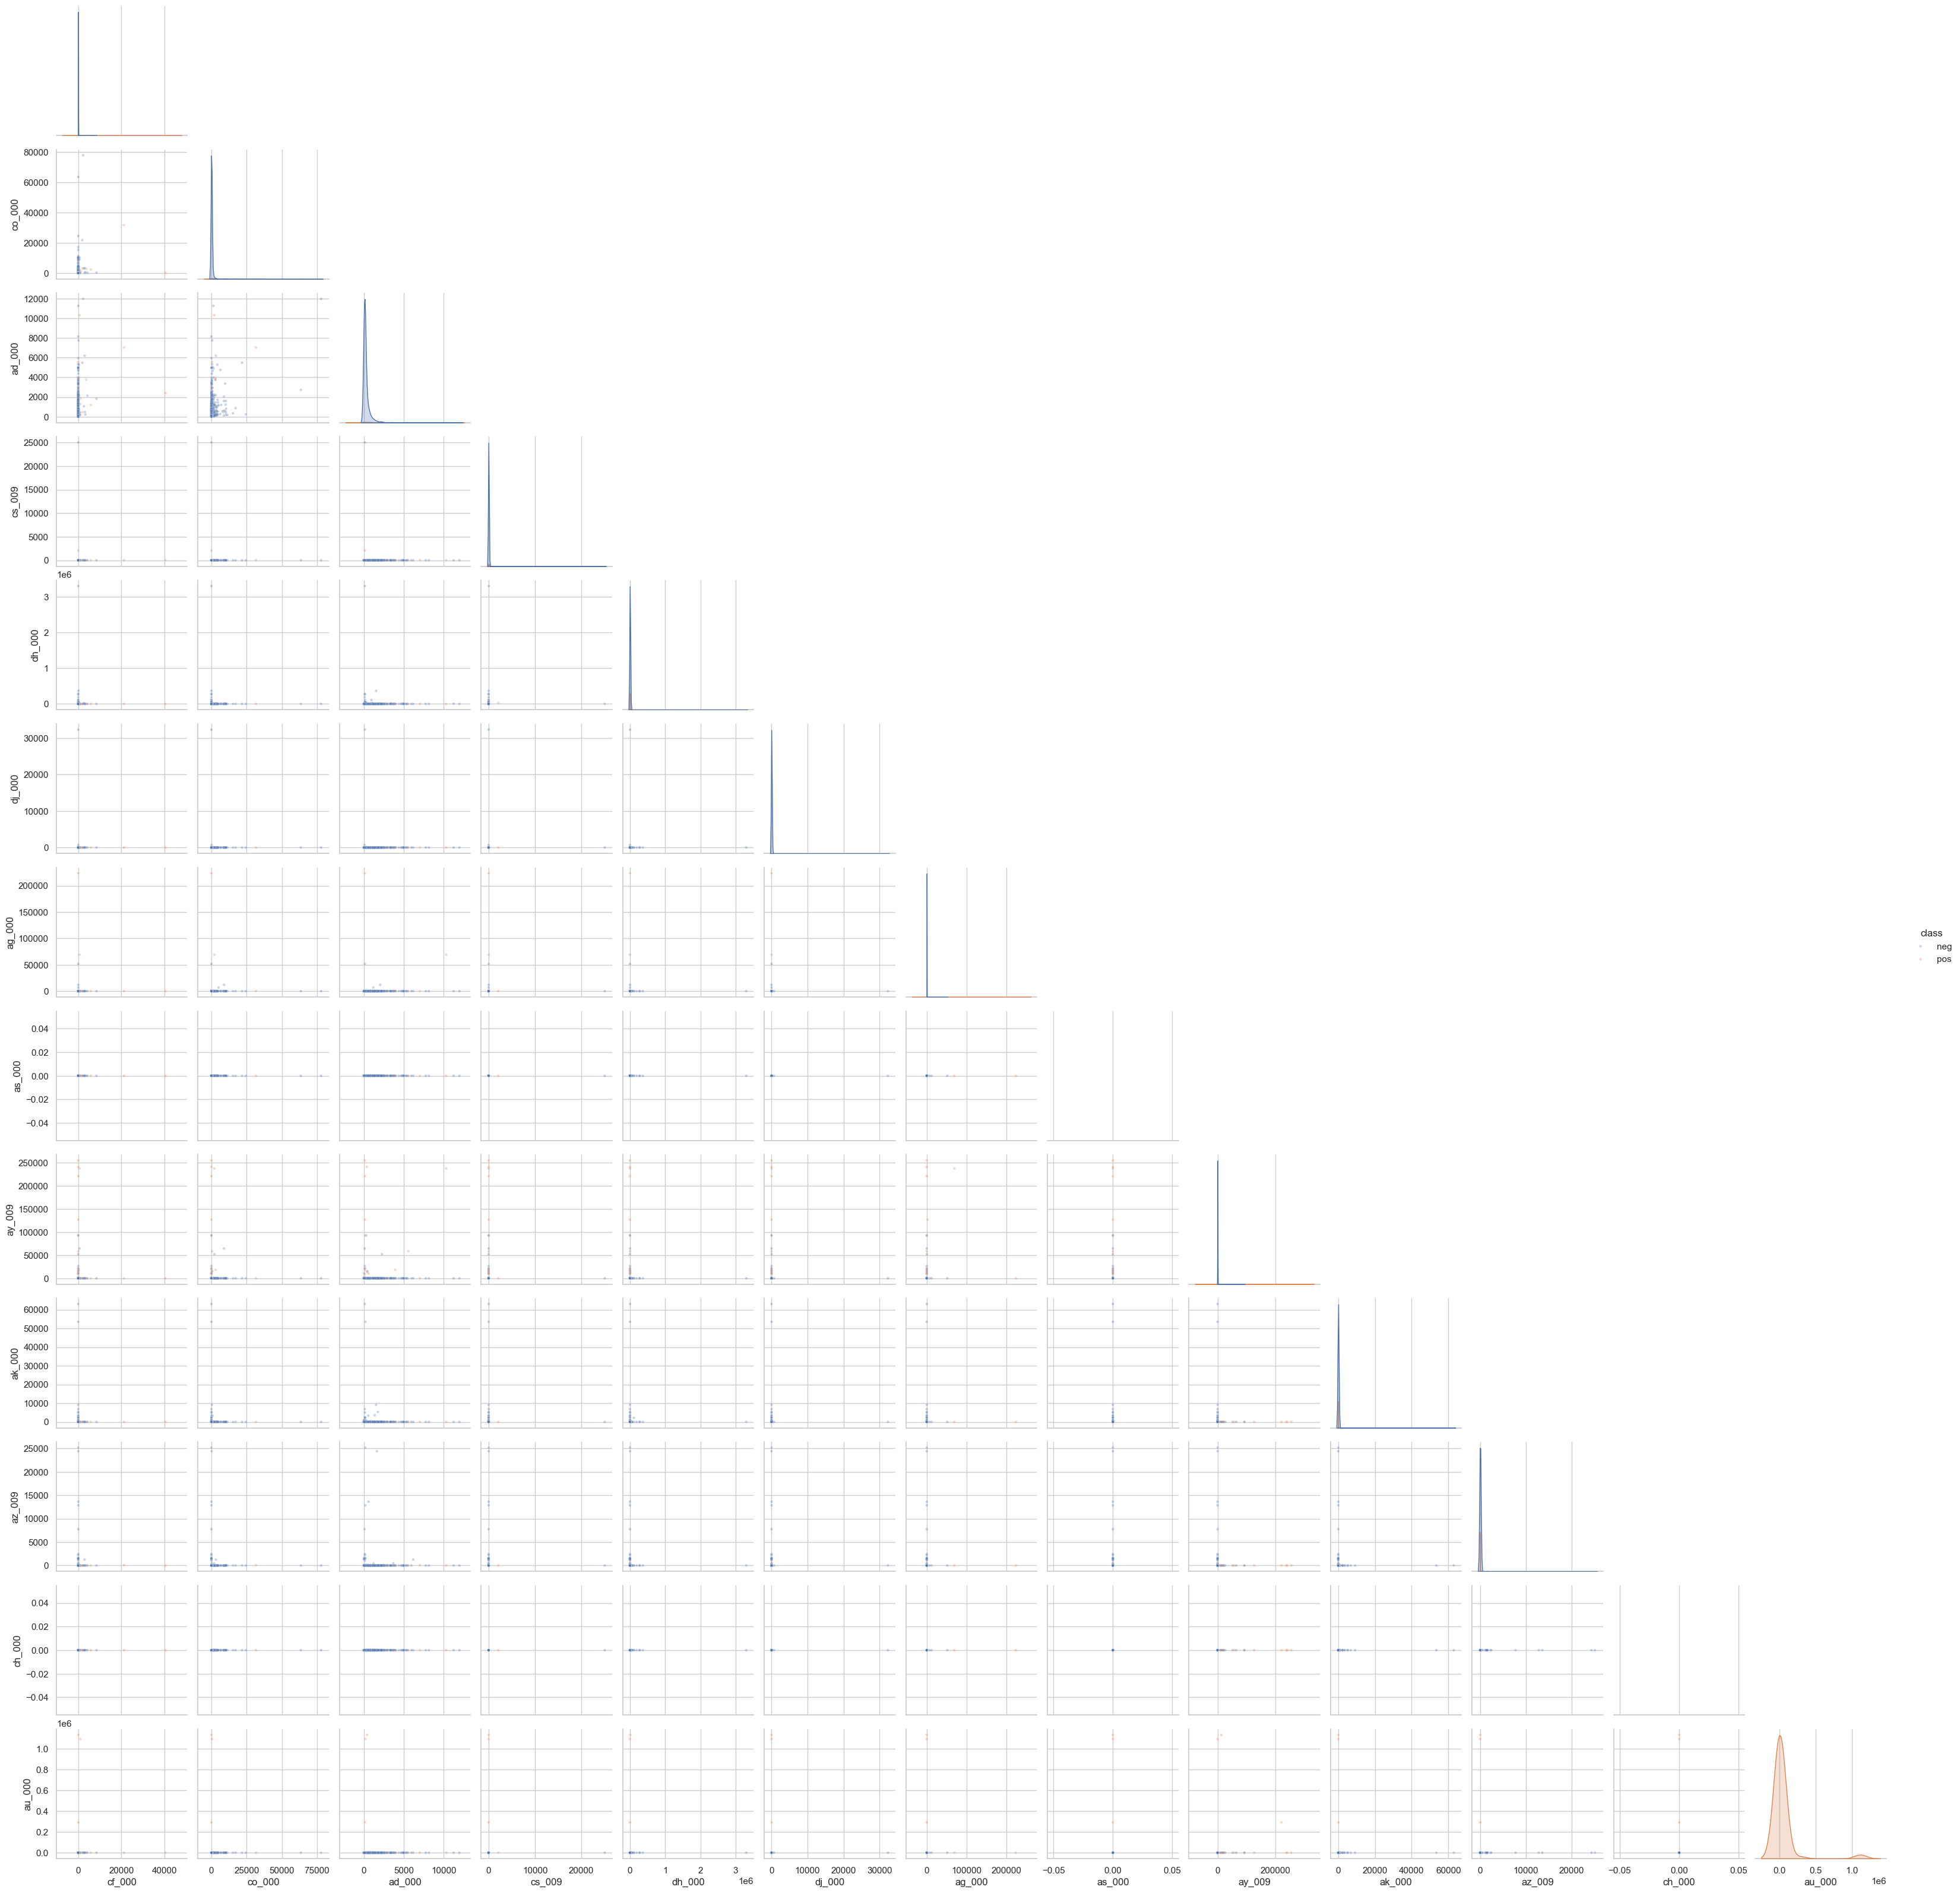

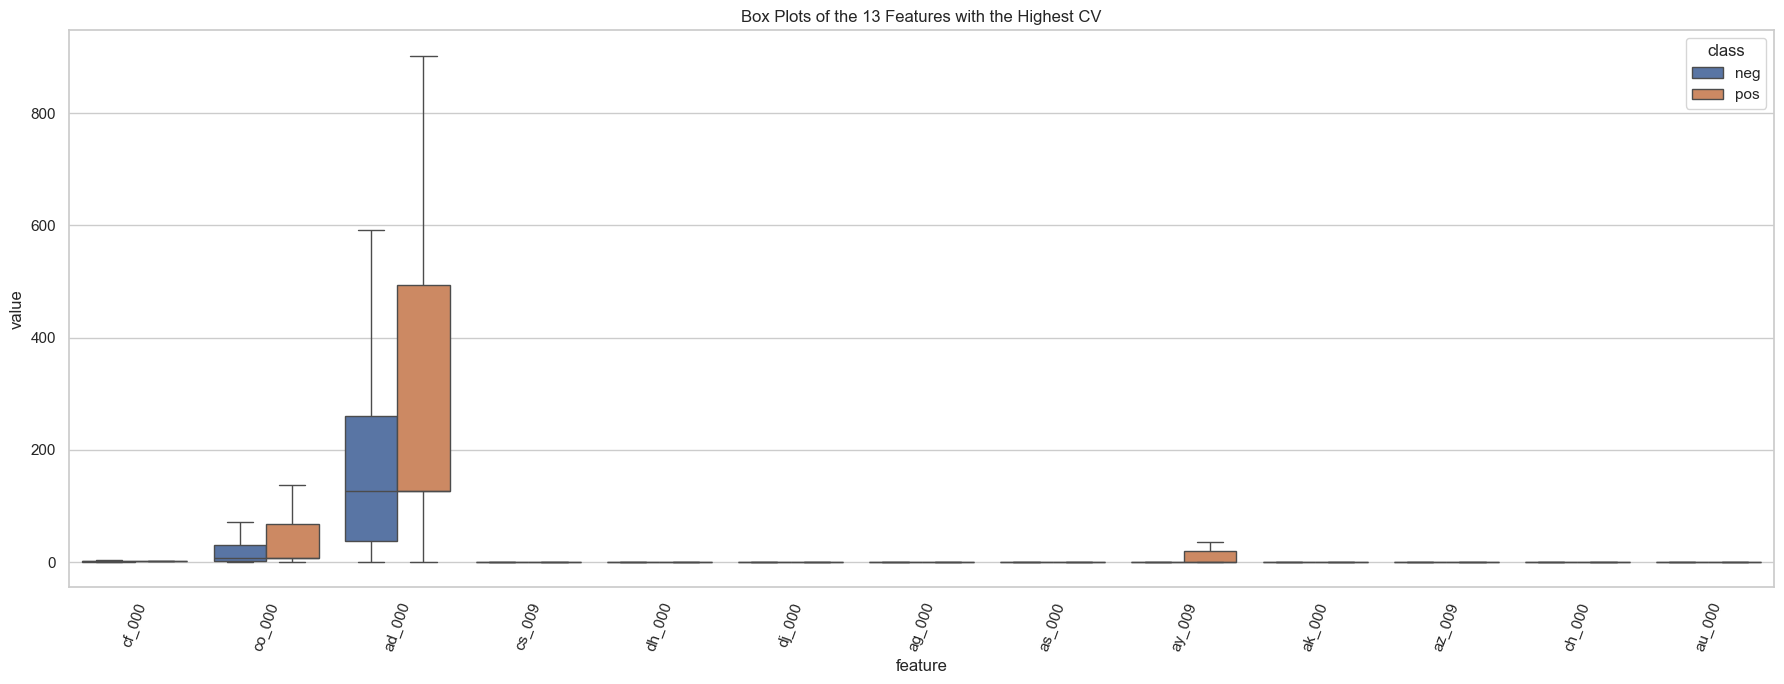

In [6]:
top_features = cv_table.index[:int(np.sqrt(len(features)))].tolist()
plot_df = X_train[top_features].copy(); plot_df['class'] = y_train.map({0:'neg', 1:'pos'})
plot_df = plot_df.sample(min(3000, len(plot_df)), random_state=RANDOM_STATE)
sns.pairplot(plot_df, hue='class', corner=True, plot_kws={'alpha':.3, 's':10}); plt.show()
long_df = plot_df.melt(id_vars='class', var_name='feature', value_name='value')
plt.figure(figsize=(18,7)); sns.boxplot(data=long_df, x='feature', y='value', hue='class', showfliers=False)
plt.xticks(rotation=70); plt.title('Box Plots of the 13 Features with the Highest CV'); plt.tight_layout(); plt.show()

#### (v) Is this data set imbalanced?

In [7]:
counts = train_raw['class'].str.strip().value_counts()
display(pd.DataFrame({'Count': counts, 'Proportion': counts / counts.sum()}))
print('Conclusion: the positive class is about 1.67%, so this is a severely imbalanced dataset; Accuracy alone is insufficient.')


,Count,Proportion
class,,
neg,59000,0.983333
pos,1000,0.016667


Conclusion: the positive class is about 1.67%, so this is a severely imbalanced dataset; Accuracy alone is insufficient.


### (c) Train a random forest


Random Forest (uncompensated) - training set
                  Predicted negative  Predicted positive
Actual negative               59000                   0
Actual positive                   0                1000
Error rate=0.0000; AUC=1.0000; Business cost=0
              precision    recall  f1-score   support

         neg     1.0000    1.0000    1.0000     59000
         pos     1.0000    1.0000    1.0000      1000

    accuracy                         1.0000     60000
   macro avg     1.0000    1.0000    1.0000     60000
weighted avg     1.0000    1.0000    1.0000     60000



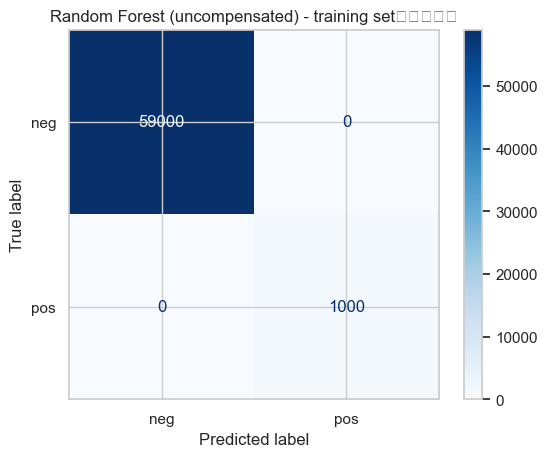

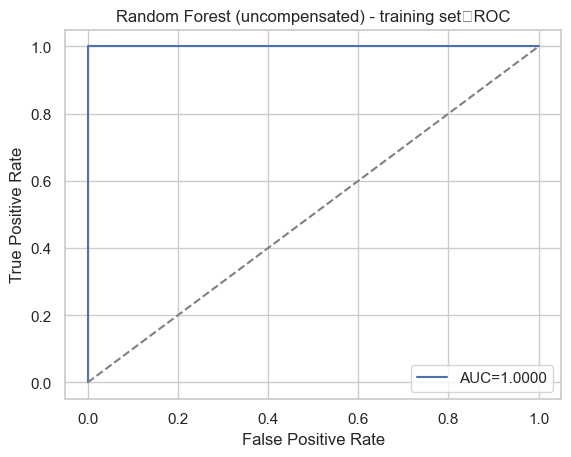


Random Forest (uncompensated) - test set
                  Predicted negative  Predicted positive
Actual negative               15608                  17
Actual positive                 106                 269
Error rate=0.0077; AUC=0.9945; Business cost=53,170
              precision    recall  f1-score   support

         neg     0.9933    0.9989    0.9961     15625
         pos     0.9406    0.7173    0.8139       375

    accuracy                         0.9923     16000
   macro avg     0.9669    0.8581    0.9050     16000
weighted avg     0.9920    0.9923    0.9918     16000



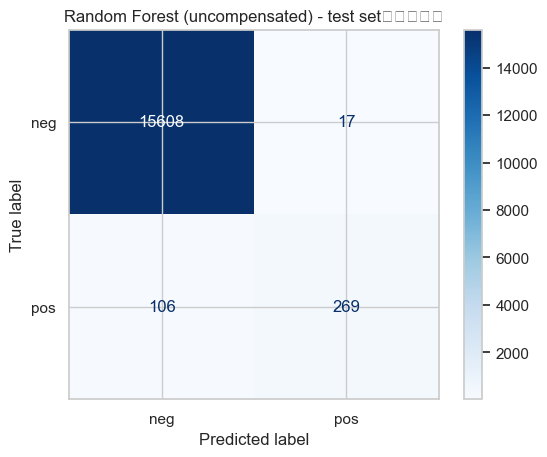

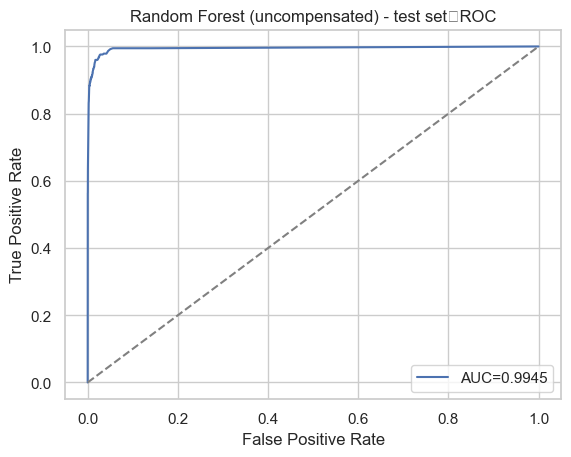

OOB error rate=0.0058; Test error rate=0.0077


In [8]:
rf_plain = RandomForestClassifier(n_estimators=300, oob_score=True, class_weight=None, random_state=RANDOM_STATE, n_jobs=N_JOBS)
rf_plain.fit(X_train, y_train)
rf_plain_train = evaluate(y_train, rf_plain.predict(X_train), rf_plain.predict_proba(X_train)[:,1], 'Random Forest (uncompensated) - training set')
rf_plain_test = evaluate(y_test, rf_plain.predict(X_test), rf_plain.predict_proba(X_test)[:,1], 'Random Forest (uncompensated) - test set')
print(f'OOB error rate={1-rf_plain.oob_score_:.4f}; Test error rate={rf_plain_test["error"]:.4f}')


### (d) Research class imbalance in random forest


Random Forest (class-weighted) - training set
                  Predicted negative  Predicted positive
Actual negative               59000                   0
Actual positive                   0                1000
Error rate=0.0000; AUC=1.0000; Business cost=0
              precision    recall  f1-score   support

         neg     1.0000    1.0000    1.0000     59000
         pos     1.0000    1.0000    1.0000      1000

    accuracy                         1.0000     60000
   macro avg     1.0000    1.0000    1.0000     60000
weighted avg     1.0000    1.0000    1.0000     60000



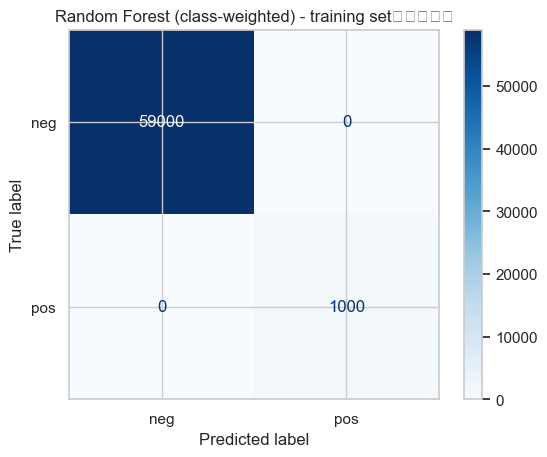

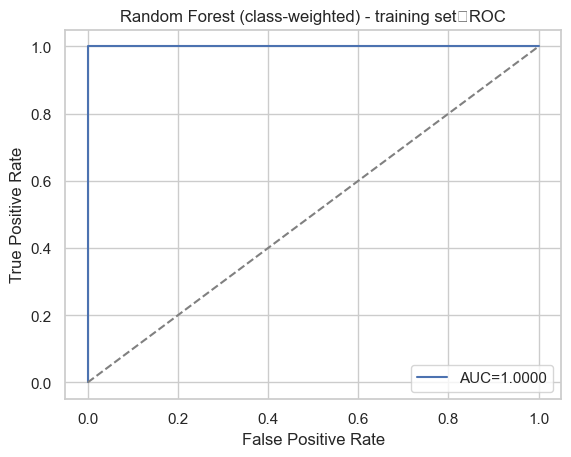


Random Forest (class-weighted) - test set
                  Predicted negative  Predicted positive
Actual negative               15610                  15
Actual positive                 157                 218
Error rate=0.0108; AUC=0.9932; Business cost=78,650
              precision    recall  f1-score   support

         neg     0.9900    0.9990    0.9945     15625
         pos     0.9356    0.5813    0.7171       375

    accuracy                         0.9892     16000
   macro avg     0.9628    0.7902    0.8558     16000
weighted avg     0.9888    0.9892    0.9880     16000



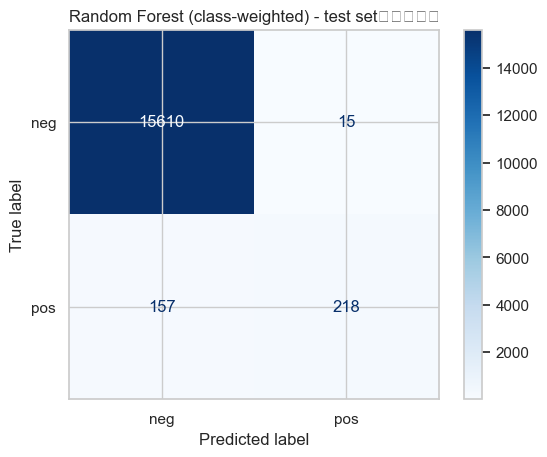

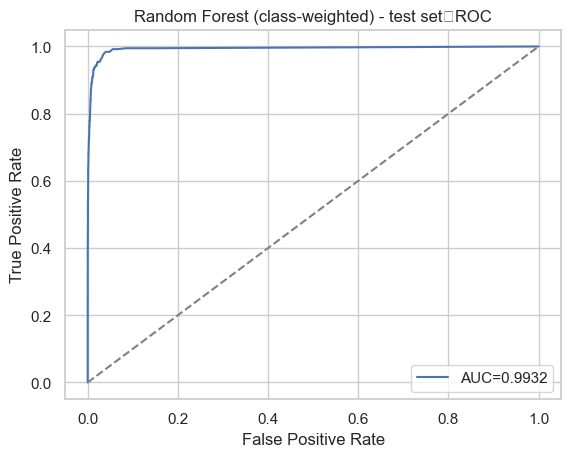

In [9]:
rf_balanced = RandomForestClassifier(n_estimators=300, oob_score=True, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=N_JOBS)
rf_balanced.fit(X_train, y_train)
rf_balanced_train = evaluate(y_train, rf_balanced.predict(X_train), rf_balanced.predict_proba(X_train)[:,1], 'Random Forest (class-weighted) - training set')
rf_balanced_test = evaluate(y_test, rf_balanced.predict(X_test), rf_balanced.predict_proba(X_test)[:,1], 'Random Forest (class-weighted) - test set')


### (e) XGBoost and Model Trees

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best alpha: 10 | CV AUC: 0.9900797033898305 | CV error rate: 0.006800000000000139

XGBoost (uncompensated) - training set
                  Predicted negative  Predicted positive
Actual negative               58964                  36
Actual positive                 176                 824
Error rate=0.0035; AUC=0.9964; Business cost=88,360
              precision    recall  f1-score   support

         neg     0.9970    0.9994    0.9982     59000
         pos     0.9581    0.8240    0.8860      1000

    accuracy                         0.9965     60000
   macro avg     0.9776    0.9117    0.9421     60000
weighted avg     0.9964    0.9965    0.9963     60000



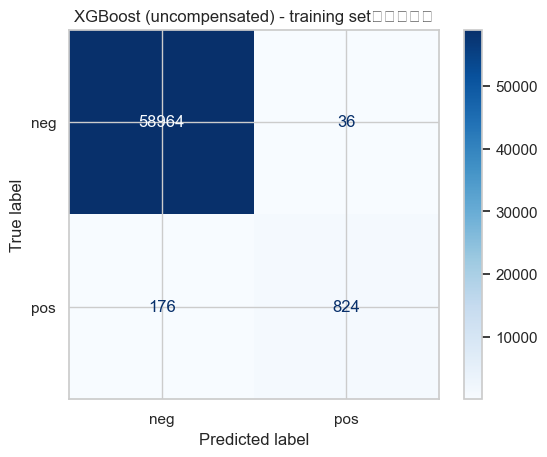

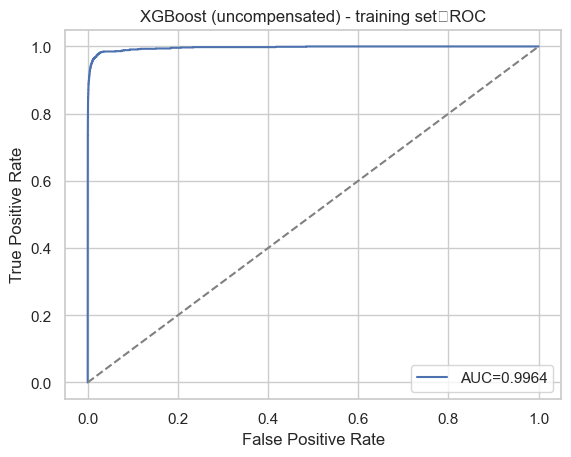


XGBoost (uncompensated) - test set
                  Predicted negative  Predicted positive
Actual negative               15607                  18
Actual positive                  98                 277
Error rate=0.0072; AUC=0.9965; Business cost=49,180
              precision    recall  f1-score   support

         neg     0.9938    0.9988    0.9963     15625
         pos     0.9390    0.7387    0.8269       375

    accuracy                         0.9928     16000
   macro avg     0.9664    0.8688    0.9116     16000
weighted avg     0.9925    0.9928    0.9923     16000



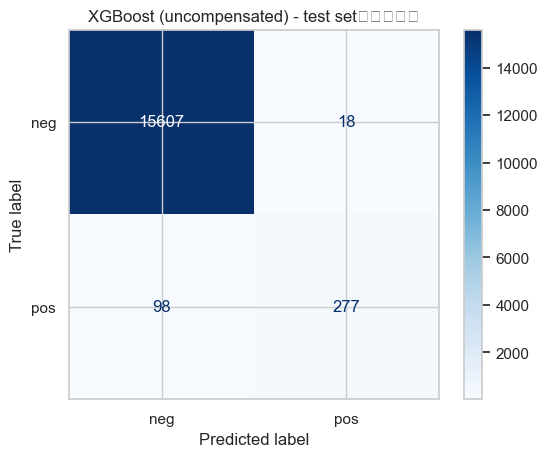

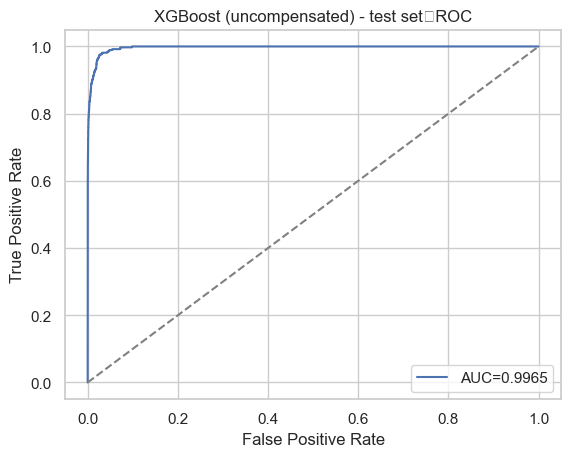

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
xgb_base = XGBClassifier(objective='binary:logistic', eval_metric='logloss', n_estimators=300, max_depth=4, learning_rate=.05, subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=N_JOBS, tree_method='hist')
# 可按照电脑性能增加 alpha 网格；当前网格已覆盖无正则至强正则。
search = GridSearchCV(xgb_base, {'reg_alpha':[0, .01, .1, 1, 10]}, scoring='roc_auc', cv=cv, n_jobs=N_JOBS, verbose=1)
search.fit(X_train, y_train); xgb_plain = search.best_estimator_
cv_accuracy = cross_val_score(xgb_plain, X_train, y_train, scoring='accuracy', cv=cv, n_jobs=N_JOBS).mean()
cv_error = 1 - cv_accuracy  # Error rate equals one minus accuracy.
print('Best alpha:', search.best_params_['reg_alpha'], '| CV AUC:', search.best_score_, '| CV error rate:', cv_error)
xgb_plain_train = evaluate(y_train, xgb_plain.predict(X_train), xgb_plain.predict_proba(X_train)[:,1], 'XGBoost (uncompensated) - training set')
xgb_plain_test = evaluate(y_test, xgb_plain.predict(X_test), xgb_plain.predict_proba(X_test)[:,1], 'XGBoost (uncompensated) - test set')


### (f) Use SMOTE to pre-process your data

SMOTE nested 5-fold CV AUC: {0: np.float64(0.9870833050847457), 0.01: np.float64(0.9871949152542372), 0.1: np.float64(0.9872483050847457), 1: np.float64(0.9868988983050848), 10: np.float64(0.9867405084745762)} | Best alpha: 0.1
Class counts after SMOTE: {0: 59000, 1: 59000}

XGBoost + SMOTE - training set
                  Predicted negative  Predicted positive
Actual negative               58604                 396
Actual positive                 112               58888
Error rate=0.0043; AUC=0.9999; Business cost=59,960
              precision    recall  f1-score   support

         neg     0.9981    0.9933    0.9957     59000
         pos     0.9933    0.9981    0.9957     59000

    accuracy                         0.9957    118000
   macro avg     0.9957    0.9957    0.9957    118000
weighted avg     0.9957    0.9957    0.9957    118000



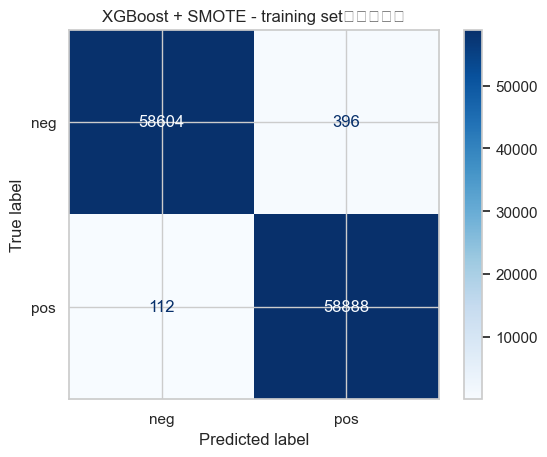

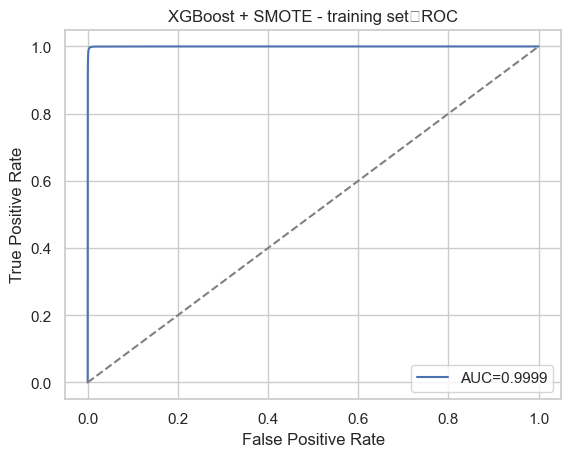


XGBoost + SMOTE - test set
                  Predicted negative  Predicted positive
Actual negative               15487                 138
Actual positive                  44                 331
Error rate=0.0114; AUC=0.9946; Business cost=23,380
              precision    recall  f1-score   support

         neg     0.9972    0.9912    0.9942     15625
         pos     0.7058    0.8827    0.7844       375

    accuracy                         0.9886     16000
   macro avg     0.8515    0.9369    0.8893     16000
weighted avg     0.9903    0.9886    0.9892     16000



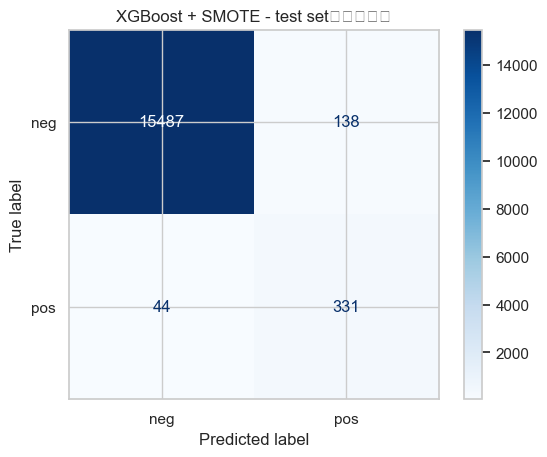

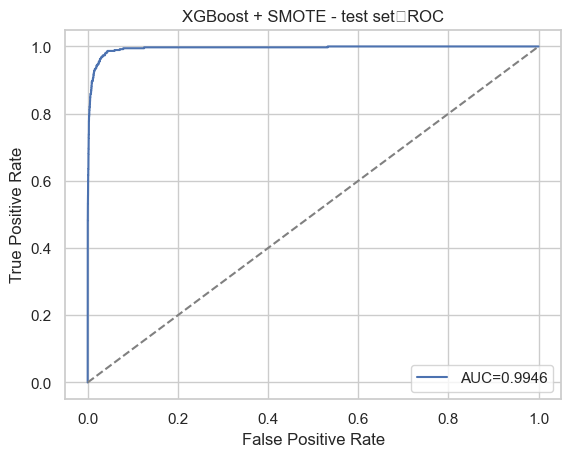

For the report, compare the uncompensated and SMOTE models by test-set FN, Recall, AUC, error rate, and business cost.


In [11]:
from sklearn.neighbors import NearestNeighbors

# 自行实现 SMOTE：只合成正类，直到正负类数量相等。
def smote_resample(X, y, k_neighbors=5, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    X_np, y_np = np.asarray(X), np.asarray(y)
    minority = X_np[y_np == 1]; majority = X_np[y_np == 0]
    n_new = len(majority) - len(minority)
    if n_new <= 0: return X_np, y_np
    nn = NearestNeighbors(n_neighbors=min(k_neighbors + 1, len(minority))).fit(minority)
    neighbor_ids = nn.kneighbors(minority, return_distance=False)[:, 1:]
    base_ids = rng.integers(len(minority), size=n_new)
    choices = rng.integers(neighbor_ids.shape[1], size=n_new)
    neighbors = minority[neighbor_ids[base_ids, choices]]
    gaps = rng.random((n_new, 1))
    synthetic = minority[base_ids] + gaps * (neighbors - minority[base_ids])
    return np.vstack([X_np, synthetic]), np.concatenate([y_np, np.ones(n_new, dtype=int)])

# 正确的 CV：对每个 alpha、每个训练折独立 SMOTE 后训练；验证折保持原始分布。
alpha_grid = [0, .01, .1, 1, 10]
smote_cv_auc = {}
for alpha in alpha_grid:
    fold_auc = []
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train)):
        X_fold, y_fold = smote_resample(X_train.iloc[tr_idx], y_train.iloc[tr_idx], random_state=RANDOM_STATE + fold)
        model = XGBClassifier(objective='binary:logistic', eval_metric='logloss', reg_alpha=alpha, n_estimators=300, max_depth=4, learning_rate=.05, subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=N_JOBS, tree_method='hist')
        model.fit(X_fold, y_fold)
        fold_auc.append(roc_auc_score(y_train.iloc[va_idx], model.predict_proba(X_train.iloc[va_idx])[:,1]))
    smote_cv_auc[alpha] = np.mean(fold_auc)
best_smote_alpha = max(smote_cv_auc, key=smote_cv_auc.get)
print('SMOTE nested 5-fold CV AUC:', smote_cv_auc, '| Best alpha:', best_smote_alpha)

# 选择 alpha 后，才在完整训练集上做一次 SMOTE，并拟合最终模型。
X_smote, y_smote = smote_resample(X_train, y_train)
print('Class counts after SMOTE:', pd.Series(y_smote).value_counts().to_dict())
xgb_smote = XGBClassifier(objective='binary:logistic', eval_metric='logloss', reg_alpha=best_smote_alpha, n_estimators=300, max_depth=4, learning_rate=.05, subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=N_JOBS, tree_method='hist')
xgb_smote.fit(X_smote, y_smote)
evaluate(y_smote, xgb_smote.predict(X_smote), xgb_smote.predict_proba(X_smote)[:,1], 'XGBoost + SMOTE - training set')
xgb_smote_test = evaluate(y_test, xgb_smote.predict(X_test), xgb_smote.predict_proba(X_test)[:,1], 'XGBoost + SMOTE - test set')
print('For the report, compare the uncompensated and SMOTE models by test-set FN, Recall, AUC, error rate, and business cost.')


## 2. ISLR 6.6.3

For the lasso constraint $\sum_{j=1}^{p}|\beta_j| \le s$:

(a) **iv. Steadily decrease.** As $s$ increases, the feasible set expands, so the minimum training RSS cannot increase.  
(b) **ii. Decrease initially, then increase in a U shape.** Test RSS may first fall as bias decreases, then rise because variance and overfitting increase.  
(c) **iii. Steadily increase.** A more flexible model has higher variance.  
(d) **iv. Steadily decrease.** Relaxing the constraint reduces squared bias.  
(e) **v. Remain constant.** Irreducible error is determined by the data-generating process, not by the model constraint.


## 3. ISLR 6.6.5

Let $x_{i1}=x_{i2}=x_i$.

(a) The ridge objective is $\sum_i (y_i-x_i(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)$.  
(b) Holding $c=\beta_1+\beta_2$ fixed, $\beta_1^2+\beta_2^2$ is minimized when $\beta_1=\beta_2=c/2$. Therefore, the ridge estimates satisfy $\hat\beta_1=\hat\beta_2$.  
(c) The lasso objective is $\sum_i (y_i-x_i(\beta_1+\beta_2))^2+\lambda(|\beta_1|+|\beta_2|)$.  
(d) If the optimal sum is $c$, all same-sign coefficient pairs satisfying $\beta_1+\beta_2=c$ have the same fitted values and L1 penalty. For example, when $c>0$, every pair $(t,c-t)$ for $0\le t\le c$ is a solution. Hence, the lasso solution is not unique.


## 4. ISLR 8.4.5

Six of the ten estimated probabilities are greater than 0.5. Therefore, **majority voting classifies the observation as Red**.

The average probability of Red is:

$$(0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75)/10=0.45.$$

Since $0.45<0.5$, **classification based on the average probability assigns the observation to Green**. The two ensemble rules can therefore produce different classifications.


## 5. ISLR 9.7.3

(a) Red observations: $(3,4),(2,2),(4,4),(1,4)$. Blue observations: $(2,1),(4,3),(4,1)$.  
(b) An optimal separating hyperplane is $1-2X_1+2X_2=0$, or equivalently $X_2=X_1-0.5$.  
(c) Classify an observation as Red if $1-2X_1+2X_2>0$; otherwise classify it as Blue.  
(d) The two margin boundaries are $X_2=X_1$ and $X_2=X_1-1$.  
(e) The support vectors are $(2,2)$ and $(4,4)$ from the Red class, and $(2,1)$ and $(4,3)$ from the Blue class.  
(f) Observation 7, $(4,1)$, is not a support vector. A small movement that does not cross a margin boundary will not change the separating hyperplane.  
(g) For example, $X_2=X_1-0.2$ is a separating hyperplane, but it is not optimal.  
(h) Adding a Blue observation at $(3,3)$ makes the two classes no longer perfectly linearly separable.


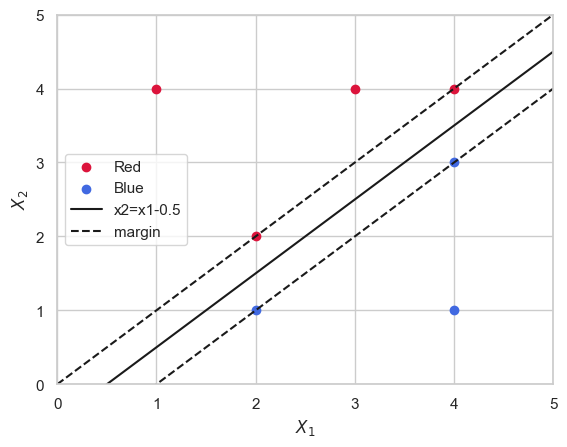

In [12]:
# 为 ISLR 9.7.3 绘制点、最优超平面和两侧 margin。
red=np.array([[3,4],[2,2],[4,4],[1,4]]); blue=np.array([[2,1],[4,3],[4,1]]); x=np.linspace(0,5,200)
plt.scatter(red[:,0],red[:,1],c='crimson',label='Red'); plt.scatter(blue[:,0],blue[:,1],c='royalblue',label='Blue')
plt.plot(x,x-.5,'k-',label='x2=x1-0.5'); plt.plot(x,x,'k--',label='margin'); plt.plot(x,x-1,'k--')
plt.xlim(0,5); plt.ylim(0,5); plt.xlabel('$X_1$'); plt.ylabel('$X_2$'); plt.legend(); plt.show()
